# FretFly: real GuitarSet clips, chroma CNN evaluation and fine-tuning

This notebook moves from synthetic audio to real guitar recordings.

It does four things:

1. loads the GuitarSet mono mic recordings and cuts the labeled chords into one second windows
2. splits the windows by recording, so no file appears in both train and validation
3. scores the synthetic-trained model on real windows to measure the gap
4. fine-tunes the model on real windows and reports results with the `Unknown` threshold

The labels come from `training/prepare_guitarset.py`, which reads the expert-verified chord layer in the GuitarSet annotations. The audio and labels stay in `data/raw`, which git ignores.

## 1. setup

In [1]:
# this cell sets the paths and audio settings for the real clips.
# the feature settings match the synthetic notebook so the two results are comparable.
import csv
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.signal import resample_poly
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 0
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

SOURCE_RATE = 44100   # guitarset wav files
SAMPLE_RATE = 22050   # rate used by the synthetic notebook
N_FFT = 2048
HOP = 512
WINDOW_SECONDS = 1.0
CHORDS = ["C", "G", "Am", "F"]

# the notebook runs from training/notebooks, so the project root is two levels up
ROOT = Path.cwd().resolve().parents[1]
CSV_PATH = ROOT / "data" / "raw" / "guitarset" / "chord_clips.csv"
MODEL_DIR = ROOT / "models"
SYNTHETIC_CHECKPOINT = MODEL_DIR / "chord_cnn_chroma.pt"
print("labels:", CSV_PATH)

labels: C:\Users\Arshan Rafid\Projects\Guitar_Chord_Vision\data\raw\guitarset\chord_clips.csv


## 2. loading the recordings

The wav files are 16-bit mono at 44.1 kHz. We convert them to float, then resample to 22.05 kHz, which is exactly half the source rate.

In [2]:
# reads a 16-bit mono wav file and resamples it to the model rate.
def load_wav(path):
    with wave.open(str(path), "rb") as handle:
        raw = handle.readframes(handle.getnframes())
    audio = np.frombuffer(raw, dtype=np.int16).astype(np.float32) / 32768.0
    return resample_poly(audio, SAMPLE_RATE, SOURCE_RATE).astype(np.float32)


# cuts every labeled segment into non-overlapping one second windows.
def build_windows(csv_path):
    windows, labels, groups = [], [], []
    current_path, current_audio = None, None
    with csv_path.open(encoding="utf-8") as handle:
        for row in csv.DictReader(handle):
            audio_path = ROOT / row["audio"]
            # rows are grouped by recording, so only one recording is held in memory
            if audio_path != current_path:
                current_path, current_audio = audio_path, load_wav(audio_path)
            start, duration = float(row["start"]), float(row["duration"])
            size = int(WINDOW_SECONDS * SAMPLE_RATE)
            for i in range(int(duration // WINDOW_SECONDS)):
                begin = int((start + i * WINDOW_SECONDS) * SAMPLE_RATE)
                if begin + size > len(current_audio):
                    continue
                windows.append(current_audio[begin : begin + size])
                labels.append(CHORDS.index(row["chord"]))
                groups.append(audio_path.stem)
    return np.stack(windows), np.array(labels), np.array(groups)


waves, labels, groups = build_windows(CSV_PATH)
print("windows:", waves.shape, "recordings:", len(np.unique(groups)))
for index, name in enumerate(CHORDS):
    print(f"  {name:>3}: {(labels == index).sum()} windows")

windows: (838, 22050) recordings: 98
    C: 248 windows
    G: 204 windows
   Am: 66 windows
    F: 320 windows


## 3. split by recording

Windows cut from the same recording share the player, the tempo, and the room. If they were split randomly, the validation score would be inflated. Instead we hold out whole recordings.

In [3]:
# holds out 20% of the recordings for validation and keeps every window from a file in one split.
files = np.unique(groups)
rng.shuffle(files)
val_files = set(files[: int(0.2 * len(files))])
is_val = np.array([g in val_files for g in groups])

print("train windows:", int((~is_val).sum()), "from", len(files) - len(val_files), "recordings")
print("val windows:  ", int(is_val.sum()), "from", len(val_files), "recordings")
for index, name in enumerate(CHORDS):
    print(f"  {name:>3}: train {int(((labels == index) & ~is_val).sum()):4d}  val {int(((labels == index) & is_val).sum()):4d}")

train windows: 675 from 79 recordings
val windows:   163 from 19 recordings
    C: train  201  val   47
    G: train  169  val   35
   Am: train   55  val   11
    F: train  250  val   70


## 4. chroma features

In [4]:
# computes the power spectrogram for a batch of clips with torch.stft.
def power_spectrogram(waves):
    window = torch.hann_window(N_FFT)
    spec = torch.stft(
        torch.from_numpy(waves), n_fft=N_FFT, hop_length=HOP, window=window, return_complex=True
    )
    return spec.abs() ** 2  # (batch, frequency bins, frames)


# folds the spectrogram into 12 pitch classes and normalizes each frame.
def chroma_features(waves):
    power = power_spectrogram(waves)
    freqs = torch.linspace(0, SAMPLE_RATE / 2, power.shape[1])
    # skip very low bins, which carry noise rather than chord pitch
    valid = freqs > 60
    midi = 69 + 12 * torch.log2(freqs.clamp(min=1e-6) / 440.0)
    pitch_class = torch.round(midi).long() % 12

    chroma = torch.zeros(waves.shape[0], 12, power.shape[2])
    for pc in range(12):
        mask = valid & (pitch_class == pc)
        chroma[:, pc, :] = power[:, mask, :].sum(dim=1)
    # normalize each frame so loudness does not affect the features
    return chroma / (chroma.sum(dim=1, keepdim=True) + 1e-8)


# runs chroma_features in chunks so the complex spectrogram fits in memory.
def chroma_in_chunks(waves, chunk=200):
    return torch.cat([chroma_features(waves[i : i + chunk]) for i in range(0, len(waves), chunk)])


chroma = chroma_in_chunks(waves)
train_x, val_x = chroma[~is_val], chroma[is_val]
train_y = torch.from_numpy(labels[~is_val])
val_y = torch.from_numpy(labels[is_val])
print("chroma:", tuple(chroma.shape), "train:", len(train_y), "val:", len(val_y))

chroma: (838, 12, 44) train: 675 val: 163


## 5. model and helpers

The model and training helpers match the synthetic notebook, so the two experiments differ only in the data.

In [5]:
# a small 1d cnn over chroma frames, the same architecture as the synthetic baseline.
class ChordCNN(nn.Module):
    def __init__(self, n_classes=len(CHORDS)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Linear(64, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).squeeze(-1))


# returns softmax probabilities for a batch of features.
@torch.no_grad()
def predict_proba(model, features):
    model.eval()
    return torch.softmax(model(features), dim=1).numpy()


# runs one pass over a loader, training when an optimizer is given.
def run_epoch(loader, model, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            count += len(y)
    return total_loss / count, correct / count


# prints a confusion matrix with rows as true chords and columns as predictions.
def print_confusion(true, pred):
    matrix = np.zeros((len(CHORDS), len(CHORDS)), dtype=int)
    for t, p in zip(true, pred):
        matrix[t, p] += 1
    print("        " + "  ".join(f"{name:>4}" for name in CHORDS))
    for name, row in zip(CHORDS, matrix):
        print(f"{name:>6}  " + "  ".join(f"{value:>4}" for value in row))

## 6. zero-shot check: the synthetic model on real clips

This is the honest test of the synthetic baseline. The model never saw a real guitar, so we expect the score to drop.

In [6]:
# loads the synthetic checkpoint and scores it on the held-out real recordings.
CONFIDENCE_THRESHOLD = 0.6
checkpoint = torch.load(SYNTHETIC_CHECKPOINT, weights_only=False)
synthetic_model = ChordCNN()
synthetic_model.load_state_dict(checkpoint["state_dict"])

probs = predict_proba(synthetic_model, val_x)
pred = probs.argmax(axis=1)
truth = val_y.numpy()
print("zero-shot validation accuracy:", round((pred == truth).mean(), 3))
print_confusion(truth, pred)
accepted = probs.max(axis=1) >= CONFIDENCE_THRESHOLD
print(f"threshold {CONFIDENCE_THRESHOLD}: {accepted.mean():.1%} accepted, accuracy on accepted {(pred[accepted] == truth[accepted]).mean():.3f}")

zero-shot validation accuracy: 0.613
           C     G    Am     F
     C    26     3     7    11
     G     2    24     7     2
    Am     2     2     4     3
     F     6    13     5    46
threshold 0.6: 93.3% accepted, accuracy on accepted 0.638


## 7. fine-tuning on real recordings

We start from the synthetic weights and train on the real training windows. The loss weights correct for the uneven chord counts, so Am does not get ignored.

In [7]:
# weights each chord by the inverse of its training count, so rare chords count for more.
counts = torch.bincount(train_y, minlength=len(CHORDS)).float()
class_weights = counts.sum() / (len(CHORDS) * counts)
print("class weights:", {name: round(float(w), 2) for name, w in zip(CHORDS, class_weights)})

train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_x, torch.from_numpy(truth)), batch_size=64)

model = ChordCNN()
model.load_state_dict(checkpoint["state_dict"])
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
# a lower learning rate keeps the synthetic features from being overwritten too fast
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

EPOCHS = 15
history = {"train_acc": [], "val_acc": []}
for epoch in range(EPOCHS):
    _, train_acc = run_epoch(train_loader, model, loss_fn, optimizer)
    _, val_acc = run_epoch(val_loader, model, loss_fn)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    print(f"epoch {epoch + 1:02d}  train acc {train_acc:.3f}  val acc {val_acc:.3f}")

class weights: {'C': 0.84, 'G': 1.0, 'Am': 3.07, 'F': 0.68}


epoch 01  train acc 0.673  val acc 0.620
epoch 02  train acc 0.687  val acc 0.638
epoch 03  train acc 0.693  val acc 0.638
epoch 04  train acc 0.693  val acc 0.632


epoch 05  train acc 0.698  val acc 0.626
epoch 06  train acc 0.707  val acc 0.632
epoch 07  train acc 0.702  val acc 0.638


epoch 08  train acc 0.707  val acc 0.644
epoch 09  train acc 0.711  val acc 0.663
epoch 10  train acc 0.708  val acc 0.663


epoch 11  train acc 0.711  val acc 0.656
epoch 12  train acc 0.714  val acc 0.669
epoch 13  train acc 0.705  val acc 0.675
epoch 14  train acc 0.704  val acc 0.687


epoch 15  train acc 0.702  val acc 0.681


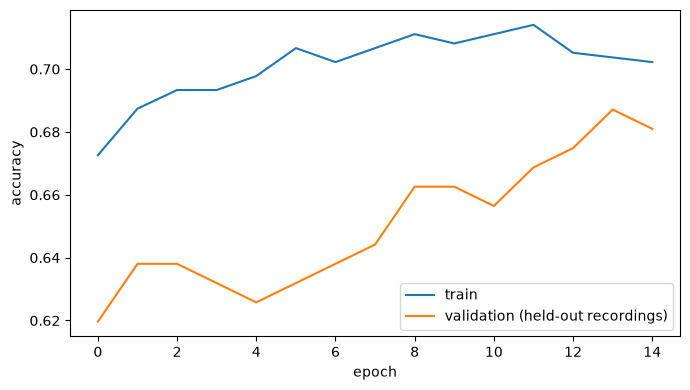

In [8]:
# plots accuracy over epochs so you can see whether the held-out recordings keep improving.
plt.figure(figsize=(7, 4))
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="validation (held-out recordings)")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## 8. final evaluation and saving

In [9]:
# scores the fine-tuned model on the held-out recordings with the Unknown rule.
probs = predict_proba(model, val_x)
pred = probs.argmax(axis=1)
print("fine-tuned validation accuracy:", round((pred == truth).mean(), 3))
print_confusion(truth, pred)
accepted = probs.max(axis=1) >= CONFIDENCE_THRESHOLD
print(f"threshold {CONFIDENCE_THRESHOLD}: {accepted.mean():.1%} accepted, accuracy on accepted {(pred[accepted] == truth[accepted]).mean():.3f}")
print("clips returned as Unknown:", int((~accepted).sum()))

fine-tuned validation accuracy: 0.681
           C     G    Am     F
     C    38     3     4     2
     G     6    24     5     0
    Am     3     1     2     5
     F     6    10     7    47
threshold 0.6: 82.2% accepted, accuracy on accepted 0.724
clips returned as Unknown: 29


In [10]:
# saves the fine-tuned weights next to the synthetic checkpoint, which stays unchanged.
MODEL_DIR.mkdir(exist_ok=True)
path = MODEL_DIR / "chord_cnn_guitarset.pt"
torch.save({
    "state_dict": model.state_dict(),
    "chords": CHORDS,
    "sample_rate": SAMPLE_RATE,
    "n_fft": N_FFT,
    "hop": HOP,
    "features": "chroma",
    "window_seconds": WINDOW_SECONDS,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
}, path)
print("saved", path)

saved C:\Users\Arshan Rafid\Projects\Guitar_Chord_Vision\models\chord_cnn_guitarset.pt


## 9. what this shows, and what it does not

**Shows:** how far the synthetic model is from real guitar audio, and how much a small real set helps when the split is by recording.

**Does not show:** performance on your own guitar, room, or webcam microphone. GuitarSet uses one studio setup with six players. The next test is a small set of clips recorded with the same microphone and setup as the app.